# 5c – Choosing the number of clusters with BIC

The third companion notebook to Example 5. A Gaussian mixture (notebook 5b) needs its number of components before it can be fitted, and RAPTOR has to choose it again for every layer of the tree. The paper:

> To determine the optimal number of clusters, we employ the Bayesian Information Criterion (BIC) for model selection. BIC not only penalizes model complexity but also rewards goodness of fit (Schwarz, 1978). The BIC for a given GMM is $BIC=\ln(N)k-2\ln(\hat{L})$, where $N$ is the number of text segments (or data points), $k$ is the number of model parameters, and $\hat{L}$ is the maximized value of the likelihood function of the model.

RAPTOR's code fits a mixture for every number of components from 1 to min(50, *N*) − 1 and keeps the one with the lowest BIC.

The notebook first builds intuition on synthetic data with a known answer: why the likelihood alone cannot choose, how the penalty works, and how much data BIC needs. Then it turns to the 30 leaves of notebook 5 and finds that they are exactly in the regime where BIC stops working – and why. It ends with the paper's complete clustering recipe applied to the same leaves.

Notation: the paper writes *k* for the number of parameters. We write ***p*** for the number of parameters and ***K*** for the number of components (scikit-learn's `n_components`).

## Imports

The same tools as in notebooks 5a and 5b, plus `sklearn.metrics.adjusted_rand_score` to compare two clusterings at the end.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import umap
from langchain_ollama import OllamaEmbeddings
from langchain_text_splitters import MarkdownHeaderTextSplitter, RecursiveCharacterTextSplitter
from matplotlib.patches import Ellipse
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from sklearn.mixture import GaussianMixture

## Configuration

- `SEED`, `N_POINTS` and the `TRUE_...` parameters – the same three-component ground truth as in notebook 5b. `MAX_K = 8` is the largest number of components we try on it.
- `DATA_FILE`, `EMBEDDING_MODEL`, `CHUNK_SIZE`, `MIN_CHARS` – notebook 5's settings for rebuilding its 30 leaves.
- `NOTEBOOK5_DIM = 8`, `NOTEBOOK5_MAX_K = 10` – what notebook 5's `cluster_nodes` uses for the 30 leaves: PCA to min(8, 30 // 3) dimensions and at most min(10, 30 // 3) components.
- `RAPTOR_DIM = 10`, `RAPTOR_THRESHOLD = 0.1`, `RAPTOR_SEED = 224` – the paper code's reduction dimension, membership threshold, and the seed it passes to the mixtures it compares.

In [2]:
SEED = 0
N_POINTS = 500
MAX_K = 8

TRUE_WEIGHTS = np.array([0.45, 0.35, 0.20])
TRUE_MEANS = np.array([[-2.5, 0.0], [1.5, 2.0], [1.8, -1.2]])
TRUE_COVARIANCES = np.array([
    [[1.0, 0.0], [0.0, 1.0]],
    [[1.6, 1.0], [1.0, 1.1]],
    [[0.35, 0.0], [0.0, 0.9]],
])

DATA_FILE = Path("data/document_a.md")
EMBEDDING_MODEL = "embeddinggemma:300m"
CHUNK_SIZE = 1200
MIN_CHARS = 80

NOTEBOOK5_DIM = 8
NOTEBOOK5_MAX_K = 10

RAPTOR_DIM = 10
RAPTOR_THRESHOLD = 0.1
RAPTOR_SEED = 224

COLORS = plt.get_cmap("tab10").colors
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 10})

Three helpers: `sample_mixture` and `draw_ellipse` as in notebook 5b, and `n_parameters(model, X)`, which reads scikit-learn's parameter count back out of its BIC. Since BIC = *p* ln *n* − 2 ln $\hat L$ and ln $\hat L$ = *n* · `model.score(X)`, the count is *p* = (BIC + 2*n* · `score`) / ln *n*.

In [3]:
def sample_mixture(n, seed):
    rng = np.random.default_rng(seed)
    components = rng.choice(len(TRUE_WEIGHTS), size=n, p=TRUE_WEIGHTS)
    points = np.array([rng.multivariate_normal(TRUE_MEANS[k], TRUE_COVARIANCES[k]) for k in components])
    return points, components


def draw_ellipse(ax, mean, covariance, color, lw=2.0):
    variances, directions = np.linalg.eigh(covariance)
    angle = np.degrees(np.arctan2(directions[1, 1], directions[0, 1]))
    for radius, style in [(1, "-"), (2, "--")]:
        ax.add_patch(Ellipse(mean, 2 * radius * np.sqrt(variances[1]), 2 * radius * np.sqrt(variances[0]),
                             angle=angle, fill=False, color=color, ls=style,
                             lw=lw if radius == 1 else lw / 2))


def n_parameters(model, X):
    return (model.bic(X) + 2 * model.score(X) * len(X)) / np.log(len(X))

## 1. More components always fit better

We sample 500 points from the three-component mixture and fit mixtures with *K* = 1 to 8 components, five restarts each (`n_init=5`). Watch what the extra components do, and what happens to the log-likelihood $\ln\hat L$ of the fitted models.

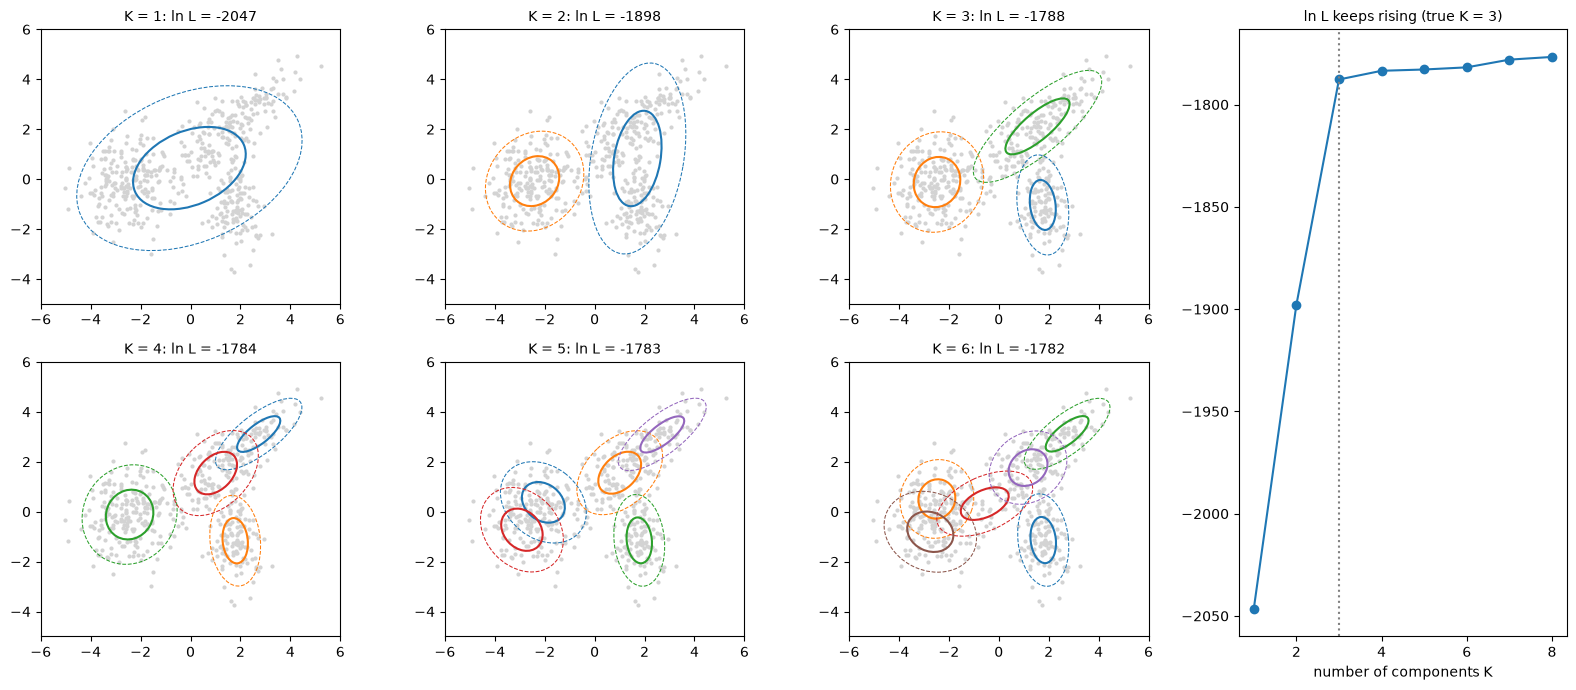

In [4]:
X, _ = sample_mixture(N_POINTS, SEED)
ks = np.arange(1, MAX_K + 1)
models = [GaussianMixture(n_components=k, n_init=5, random_state=SEED).fit(X) for k in ks]
log_likelihood = np.array([model.score(X) * len(X) for model in models])

fig = plt.figure(figsize=(16, 7))
for position, model in enumerate(models[:6]):
    ax = fig.add_subplot(2, 4, position + 1 + (position >= 3))
    ax.scatter(X[:, 0], X[:, 1], s=4, color="lightgray")
    for k in range(model.n_components):
        draw_ellipse(ax, model.means_[k], model.covariances_[k], COLORS[k], lw=1.5)
    ax.set_title(f"K = {model.n_components}: ln L = {log_likelihood[position]:.0f}")
    ax.set_xlim(-6, 6)
    ax.set_ylim(-5, 6)
    ax.set_aspect("equal")
ax = fig.add_subplot(1, 4, 4)
ax.plot(ks, log_likelihood, "o-")
ax.axvline(3, color="gray", ls=":")
ax.set_xlabel("number of components K")
ax.set_title("ln L keeps rising (true K = 3)")
fig.tight_layout()
plt.show()

With *K* = 1 a single ellipse covers everything, *K* = 3 recovers the three groups, and from *K* = 4 on the extra components split a group or wrap a few outlying points. Yet $\ln\hat L$ keeps rising, because a model with more components contains the smaller models as special cases and can always fit the data it was fitted to at least as well. The likelihood measures fit, not truth; on its own it would always choose the largest *K*.

## 2. The Bayesian Information Criterion

BIC charges a price for every parameter:

$$\mathrm{BIC}=p\,\ln n\;-\;2\ln\hat L .$$

Lower is better. The first term grows with the number of parameters *p*, the second falls as the fit improves. A model with more parameters wins only if its log-likelihood improves by more than ln(*n*)/2 per extra parameter – for 500 points about 3.1 per parameter, or about 19 for one more 2-D component, which brings 6 parameters.

For a mixture of *K* full-covariance Gaussians in *d* dimensions

$$p=\underbrace{K\,d}_{\text{means}}+\underbrace{K\,\tfrac{d(d+1)}{2}}_{\text{covariances}}+\underbrace{K-1}_{\text{weights}},$$

where the weights count *K* − 1 because they must add up to 1. The cell checks the formula against the count scikit-learn uses.

Where does BIC come from? Schwarz (1978) derived it as an approximation of the Bayesian probability of the data under each model (the *evidence*). The approximation holds when *n* is large and the maximum of the likelihood is a regular, well-behaved peak – keep both conditions in mind; section 5 is about what happens when the second one fails. The Akaike Information Criterion, AIC = 2*p* − 2 ln $\hat L$, has a penalty that does not grow with *n*; it aims at predictive accuracy rather than at the true number of components and tends to choose more of them.

In [5]:
d = X.shape[1]
for model in models:
    k = model.n_components
    formula = k * d + k * d * (d + 1) // 2 + (k - 1)
    print(f"K = {k}: formula {formula:3d}, scikit-learn {n_parameters(model, X):5.1f}")

K = 1: formula   5, scikit-learn   5.0
K = 2: formula  11, scikit-learn  11.0
K = 3: formula  17, scikit-learn  17.0
K = 4: formula  23, scikit-learn  23.0
K = 5: formula  29, scikit-learn  29.0
K = 6: formula  35, scikit-learn  35.0
K = 7: formula  41, scikit-learn  41.0
K = 8: formula  47, scikit-learn  47.0


The left panel shows the two terms of BIC side by side, both as changes from *K* = 1 so that they share a scale; the right panel compares BIC with AIC, each relative to its own minimum.

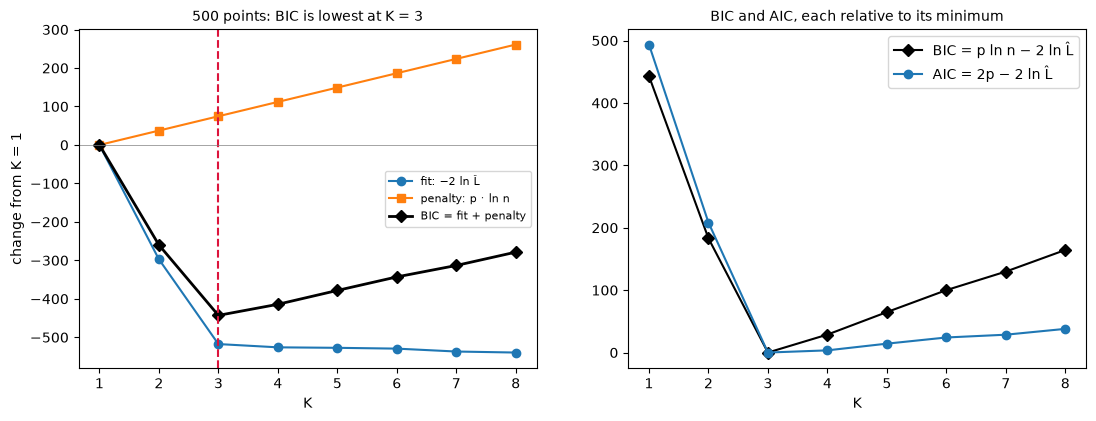

In [6]:
fit = -2 * log_likelihood
penalty = np.array([n_parameters(model, X) for model in models]) * np.log(len(X))
bic = np.array([model.bic(X) for model in models])
aic = np.array([model.aic(X) for model in models])
best_k = ks[np.argmin(bic)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].plot(ks, fit - fit[0], "o-", label="fit: −2 ln L̂")
axes[0].plot(ks, penalty - penalty[0], "s-", label="penalty: p · ln n")
axes[0].plot(ks, bic - bic[0], "D-", color="black", lw=2, label="BIC = fit + penalty")
axes[0].axvline(best_k, color="crimson", ls="--")
axes[0].axhline(0, color="gray", lw=0.5)
axes[0].set_xlabel("K")
axes[0].set_ylabel("change from K = 1")
axes[0].set_title(f"{len(X)} points: BIC is lowest at K = {best_k}")
axes[0].legend(fontsize=8)
axes[1].plot(ks, bic - bic.min(), "D-", color="black", label="BIC = p ln n − 2 ln L̂")
axes[1].plot(ks, aic - aic.min(), "o-", label="AIC = 2p − 2 ln L̂")
axes[1].set_xlabel("K")
axes[1].set_title("BIC and AIC, each relative to its minimum")
axes[1].legend()
plt.show()

The fit term falls steeply up to *K* = 3 and then hardly moves, while the penalty grows by the same amount for every component; their sum has its minimum at the true *K* = 3. AIC agrees here, but its curve beyond the minimum is much flatter – with a bit more noise it would tip towards a larger *K*.

## 3. How many points does BIC need?

BIC's justification is asymptotic: it holds for large *n*. To see what "large" means, we draw 25 samples of every size from 10 to 1,280 points from the same mixture, let BIC choose *K* between 1 and 6 for each sample (two restarts per fit), and count the choices. This cell fits about 1,200 mixtures and takes a few seconds.

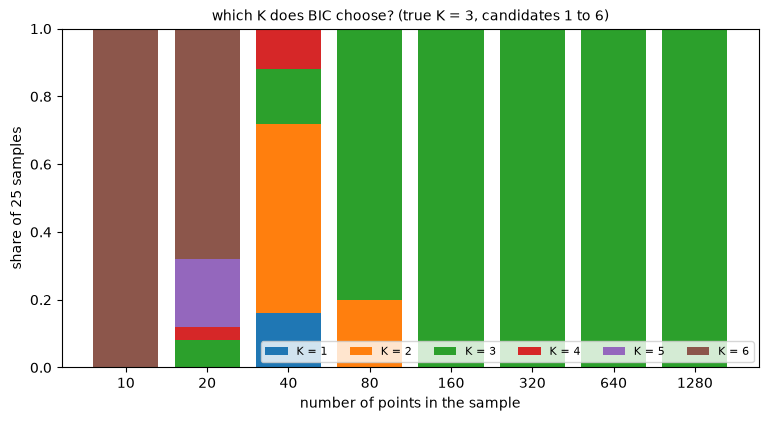

In [7]:
sizes = [10, 20, 40, 80, 160, 320, 640, 1280]
repetitions = 25
chosen = {size: [] for size in sizes}
for size in sizes:
    for repetition in range(repetitions):
        subset, _ = sample_mixture(size, 1000 + repetition)
        scores = [GaussianMixture(n_components=k, n_init=2, random_state=SEED).fit(subset).bic(subset)
                  for k in range(1, 7)]
        chosen[size].append(int(np.argmin(scores)) + 1)

fig, ax = plt.subplots(figsize=(9, 4.4))
bottom = np.zeros(len(sizes))
for k in range(1, 7):
    share = np.array([np.mean(np.array(chosen[size]) == k) for size in sizes])
    ax.bar([str(size) for size in sizes], share, bottom=bottom, color=COLORS[k - 1], label=f"K = {k}")
    bottom += share
ax.set_xlabel("number of points in the sample")
ax.set_ylabel(f"share of {repetitions} samples")
ax.set_title("which K does BIC choose? (true K = 3, candidates 1 to 6)")
ax.legend(ncol=6, fontsize=8, loc="lower right")
plt.show()

Three regimes:

- **10–20 points: BIC chooses the *largest* K on offer** – every time at 10 points, mostly at 20. This is not caution failing; it is the likelihood breaking. With 10 points and 6 components some components hold one or two points, collapse onto them, and their likelihood explodes (section 5 explains why). No finite penalty can compete with that.
- **Around 40 points: too few.** The components are well defined now, but the evidence for a third group is weak, and BIC mostly settles for one or two. This is BIC working as designed: with little data, prefer the simpler model.
- **From 160 points on: always right.** That is about 50 points per component in 2 dimensions.

## 4. Parameters grow with the dimension

How many points a component needs depends on how many numbers it has to estimate, and for a full covariance that number grows with the square of the dimension.

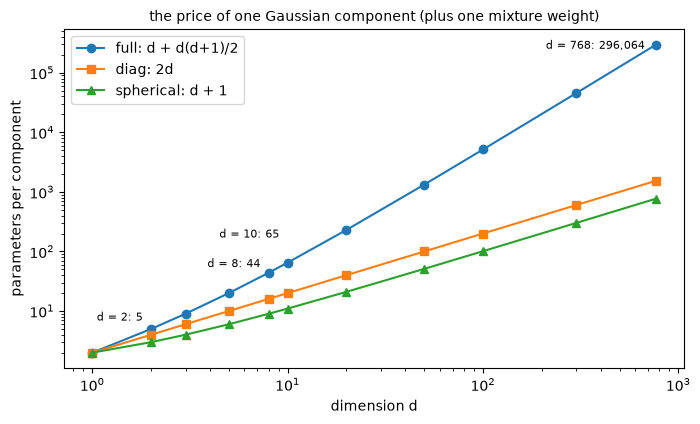

In [8]:
dimensions = np.array([1, 2, 3, 5, 8, 10, 20, 50, 100, 300, 768])
full = dimensions + dimensions * (dimensions + 1) // 2

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.loglog(dimensions, full, "o-", label="full: d + d(d+1)/2")
ax.loglog(dimensions, 2 * dimensions, "s-", label="diag: 2d")
ax.loglog(dimensions, dimensions + 1, "^-", label="spherical: d + 1")
for dim, offset in [(2, (-6, 6)), (8, (-6, 4)), (10, (-6, 18)), (768, (-8, -3))]:
    ax.annotate(f"d = {dim}: {dim + dim * (dim + 1) // 2:,}", (dim, dim + dim * (dim + 1) / 2),
                textcoords="offset points", xytext=offset, ha="right", fontsize=8)
ax.set_xlabel("dimension d")
ax.set_ylabel("parameters per component")
ax.set_title("the price of one Gaussian component (plus one mixture weight)")
ax.legend()
plt.show()

A full Gaussian has 5 parameters in 2 dimensions, 44 in 8, 65 in 10 and 296,064 in 768; diagonal and spherical covariances grow only linearly. And below every statistical notion of "enough" there is a hard floor: a covariance matrix estimated from *m* points has rank at most *m* − 1, so a full-covariance component needs at least *d* + 1 points just to be non-singular. Notebook 5 clusters 30 leaves in 8 dimensions into clusters of three to six leaves – below the floor. Section 5 shows what that does.

## 5. When the likelihood breaks: fewer points than dimensions

The smallest possible example: one Gaussian fitted to two points in 2 dimensions. Two points always lie on a line, so the fitted covariance has a direction with zero variance, and the ellipse collapses onto the segment between them. What keeps it from collapsing completely is scikit-learn's `reg_covar`, a small number (by default 10⁻⁶) added to the diagonal of every covariance matrix. We vary it from 10⁻¹ to 10⁻⁹.

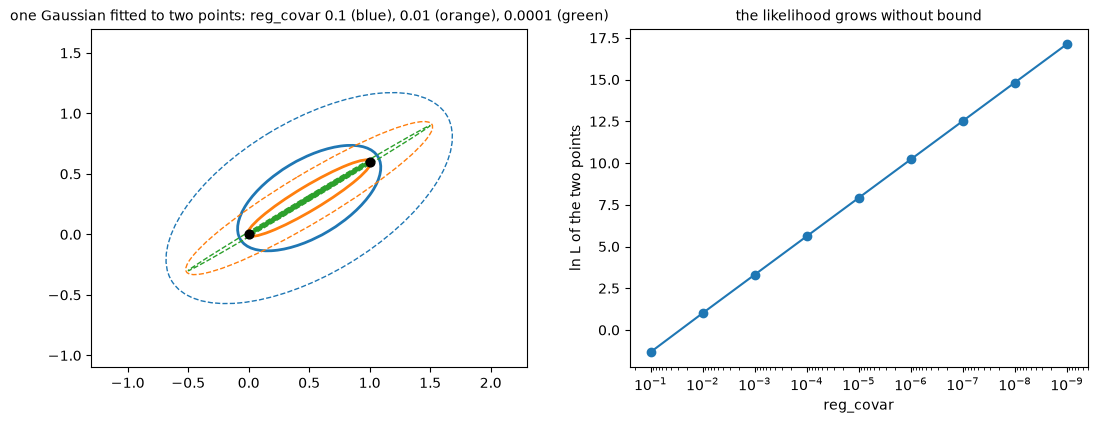

In [9]:
two_points = np.array([[0.0, 0.0], [1.0, 0.6]])
reg_values = np.logspace(-1, -9, 9)
two_point_log_likelihood = [GaussianMixture(n_components=1, reg_covar=reg).fit(two_points).score(two_points) * 2
                            for reg in reg_values]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for reg, color in [(1e-1, "tab:blue"), (1e-2, "tab:orange"), (1e-4, "tab:green")]:
    model = GaussianMixture(n_components=1, reg_covar=reg).fit(two_points)
    draw_ellipse(axes[0], model.means_[0], model.covariances_[0], color)
axes[0].scatter(two_points[:, 0], two_points[:, 1], color="black", s=40, zorder=5)
axes[0].set_xlim(-1.3, 2.3)
axes[0].set_ylim(-1.1, 1.7)
axes[0].set_aspect("equal")
axes[0].set_title("one Gaussian fitted to two points: reg_covar 0.1 (blue), 0.01 (orange), 0.0001 (green)")
axes[1].semilogx(reg_values, two_point_log_likelihood, "o-")
axes[1].invert_xaxis()
axes[1].set_xlabel("reg_covar")
axes[1].set_ylabel("ln L of the two points")
axes[1].set_title("the likelihood grows without bound")
plt.show()

The thinner the ellipse, the higher the density along the segment – the determinant $|\Sigma|$ in the normalisation goes to 0 (notebook 5b, section 1) – and the log-likelihood of the two points grows by about 2.3 for every factor of 10 in `reg_covar` (½ ln 10 ≈ 1.15 per point), without limit. The model does not describe the data any better in a meaningful sense; it exploits a degenerate direction.

The same happens in *d* dimensions whenever a component holds *m* ≤ *d* points. The *m* points span at most *m* − 1 directions, so *d* − *m* + 1 eigenvalues of the fitted covariance sit at `reg_covar`, and each of those directions adds roughly ½ ln(σ² / `reg_covar`) to the log-likelihood of every point in the component, where σ² is the data's natural variance. More components mean smaller components mean more collapsed directions. The likelihood gain from splitting no longer measures structure, and BIC's finite penalty cannot stop it. That was the first regime of section 3.

## 6. Back to the 30 leaves of notebook 5

The cell rebuilds and embeds the leaves exactly as notebook 5 does, then repeats what notebook 5's `cluster_nodes` does for the first layer of the tree: PCA to `NOTEBOOK5_DIM` = 8 dimensions, mixtures with *K* = 1 to `NOTEBOOK5_MAX_K` = 10 components, five restarts, `random_state=0`.

In [10]:
text = DATA_FILE.read_text(encoding="utf-8").replace("\\$", "$")
text = "\n".join(line for line in text.splitlines() if line.strip() != "---")
headers = [("#", "h1"), ("##", "h2"), ("###", "h3"), ("####", "h4")]
splitter = RecursiveCharacterTextSplitter(
    chunk_size=CHUNK_SIZE,
    chunk_overlap=0,
    separators=["\n\n", "\n", r"(?<=</tr>)", r"(?<=\. )", " ", ""],
    is_separator_regex=True,
)
sections = MarkdownHeaderTextSplitter(headers_to_split_on=headers).split_text(text)
pieces = [p for p in splitter.split_documents(sections) if len(p.page_content) >= MIN_CHARS]


def breadcrumb(metadata):
    return " > ".join(metadata[k] for k in ("h1", "h2", "h3", "h4") if k in metadata)


def short_label(metadata):
    if metadata.get("h2") != "Notes to Financial Statements":
        return metadata.get("h3", metadata["h2"])
    note = metadata["h3"].split(" - ")[0].replace("Note ", "N")
    return f"{note} {metadata.get('h4', metadata['h3'].split(' - ')[1])}"


leaves = [f"{breadcrumb(p.metadata)}\n\n{p.page_content}" for p in pieces]
names = [short_label(p.metadata) for p in pieces]
leaf_vectors = np.array(OllamaEmbeddings(model=EMBEDDING_MODEL).embed_documents(leaves))
print(f"{len(leaves)} leaves, vectors of shape {leaf_vectors.shape}")

leaves_8d = PCA(n_components=NOTEBOOK5_DIM, random_state=0).fit_transform(leaf_vectors)
candidates = [GaussianMixture(n_components=k, n_init=5, random_state=0).fit(leaves_8d)
              for k in range(1, NOTEBOOK5_MAX_K + 1)]
leaf_bic = [model.bic(leaves_8d) for model in candidates]
notebook5_model = candidates[int(np.argmin(leaf_bic))]
cluster_sizes = np.bincount(notebook5_model.predict(leaves_8d), minlength=notebook5_model.n_components)
print(f"BIC chooses K = {notebook5_model.n_components}, cluster sizes {cluster_sizes.tolist()}")

30 leaves, vectors of shape (30, 768)
BIC chooses K = 8, cluster sizes [3, 5, 6, 3, 4, 3, 3, 3]


The left panel is the BIC curve notebook 5 saw when it built the first layer of its tree. The right panel shows the eigenvalues of the fitted covariance matrices of the chosen model, largest first, on a logarithmic scale, with the `reg_covar` floor as a dashed line.

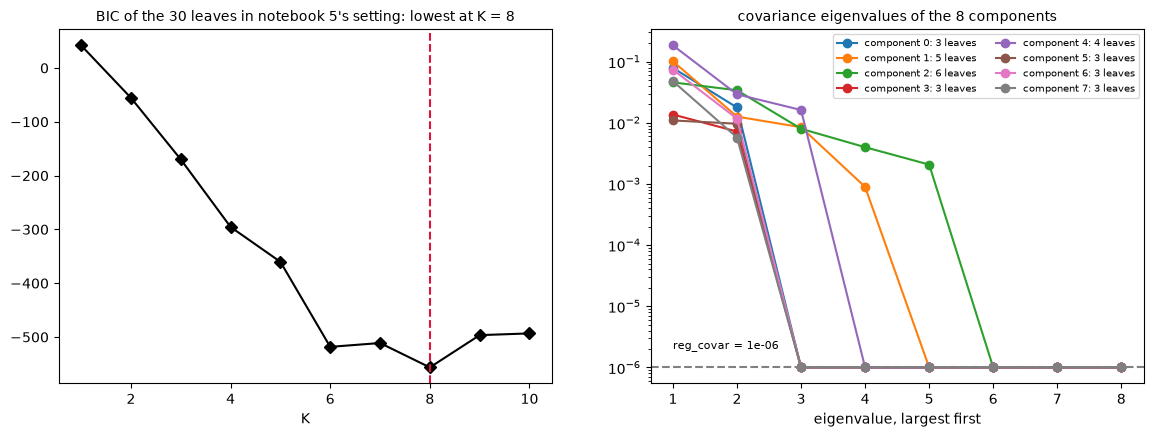

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].plot(range(1, NOTEBOOK5_MAX_K + 1), leaf_bic, "D-", color="black")
axes[0].axvline(notebook5_model.n_components, color="crimson", ls="--")
axes[0].set_xlabel("K")
axes[0].set_title(f"BIC of the 30 leaves in notebook 5's setting: lowest at K = {notebook5_model.n_components}")
for k, covariance in enumerate(notebook5_model.covariances_):
    eigenvalues = np.sort(np.linalg.eigvalsh(covariance))[::-1]
    axes[1].semilogy(range(1, NOTEBOOK5_DIM + 1), eigenvalues, "o-", color=COLORS[k % 10],
                     label=f"component {k}: {cluster_sizes[k]} leaves")
axes[1].axhline(notebook5_model.reg_covar, color="gray", ls="--")
axes[1].text(1, notebook5_model.reg_covar * 2, f"reg_covar = {notebook5_model.reg_covar:g}", fontsize=8)
axes[1].set_xlabel("eigenvalue, largest first")
axes[1].set_title(f"covariance eigenvalues of the {notebook5_model.n_components} components")
axes[1].legend(fontsize=7, ncol=2)
plt.show()

Every component is degenerate. A component with three leaves has exactly two eigenvalues above the floor and six on it; one with six leaves has five and three – precisely the rule that *m* points span *m* − 1 directions. The BIC curve falls for the same reason the 10-point samples of section 3 chose the largest *K*: smaller components mean more collapsed directions, and every collapsed direction pays off in likelihood. The choice is a consequence of the ratio between leaves and dimensions, not a property of the document.

This does not make notebook 5's clusters bad: the component means behave like k-means centres, and the clusters printed in notebook 5 are topically coherent. But the *number* of clusters must not be read as "the document has eight topics".

### How much does the choice depend on the setting?

If BIC measured a property of the data, reasonable variations of the set-up would agree. We let BIC choose *K* (1 to 10) under seven settings: PCA to 2, 3 and 8 dimensions with full covariances; PCA to 8 dimensions with diagonal and spherical covariances; UMAP (cosine, 5 neighbours) to 2 and to 10 dimensions, the last being the paper's setting. A setting counts as degenerate (red) if any variance of its chosen model is within a factor of 10 of `reg_covar`; `smallest_variance(model)` handles the different storage formats of the covariance types.

PCA 2-d, full                K =  2  sizes [24, 6]
PCA 3-d, full                K = 10  sizes [3, 3, 4, 4, 3, 2, 4, 3, 2, 2]
PCA 8-d, full (notebook 5)   K =  8  sizes [3, 5, 6, 3, 4, 3, 3, 3]
PCA 8-d, diag                K =  4  sizes [1, 5, 6, 18]
PCA 8-d, spherical           K =  4  sizes [1, 3, 6, 20]
UMAP 2-d, full               K =  1  sizes [30]
UMAP 10-d, full (paper)      K =  5  sizes [5, 6, 6, 8, 5]


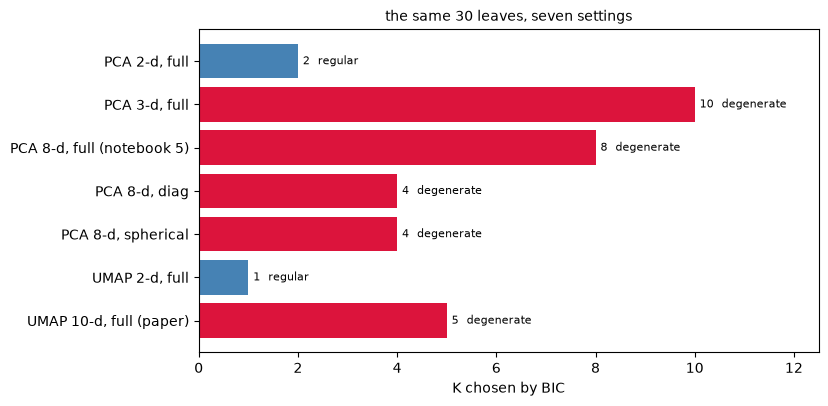

In [12]:
def smallest_variance(model):
    if model.covariance_type == "full":
        return min(np.linalg.eigvalsh(covariance).min() for covariance in model.covariances_)
    return float(np.min(model.covariances_))


def umap_reduce(vectors, dimensions, seed=SEED):
    return umap.UMAP(n_neighbors=int((len(vectors) - 1) ** 0.5), n_components=dimensions,
                     metric="cosine", random_state=seed, n_jobs=1).fit_transform(vectors)


settings = [
    ("PCA 2-d, full", PCA(n_components=2, random_state=0).fit_transform(leaf_vectors), "full"),
    ("PCA 3-d, full", PCA(n_components=3, random_state=0).fit_transform(leaf_vectors), "full"),
    ("PCA 8-d, full (notebook 5)", leaves_8d, "full"),
    ("PCA 8-d, diag", leaves_8d, "diag"),
    ("PCA 8-d, spherical", leaves_8d, "spherical"),
    ("UMAP 2-d, full", umap_reduce(leaf_vectors, 2), "full"),
    ("UMAP 10-d, full (paper)", umap_reduce(leaf_vectors, RAPTOR_DIM), "full"),
]
results = []
for name, points, covariance_type in settings:
    fits = [GaussianMixture(n_components=k, covariance_type=covariance_type, n_init=5, random_state=0).fit(points)
            for k in range(1, NOTEBOOK5_MAX_K + 1)]
    best = min(fits, key=lambda model: model.bic(points))
    sizes_best = np.bincount(best.predict(points), minlength=best.n_components)
    results.append((name, best.n_components, smallest_variance(best) < 10 * best.reg_covar))
    print(f"{name:28} K = {best.n_components:2d}  sizes {sizes_best.tolist()}")

fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(results))[::-1]
ax.barh(y, [k for _, k, _ in results], color=["crimson" if bad else "steelblue" for _, _, bad in results])
for position, (_, k, bad) in zip(y, results):
    ax.text(k + 0.1, position, f"{k}  {'degenerate' if bad else 'regular'}", va="center", fontsize=8)
ax.set_yticks(y)
ax.set_yticklabels([name for name, _, _ in results])
ax.set_xlim(0, NOTEBOOK5_MAX_K + 2.5)
ax.set_xlabel("K chosen by BIC")
ax.set_title("the same 30 leaves, seven settings")
plt.show()

The seven settings choose between one and ten clusters. Every setting with three or more dimensions, including the paper's, ends up degenerate (red) and chooses one of the larger values, for the reason shown in section 5; for the diagonal and spherical models the degeneracy comes from a component that holds a single leaf. Only the two 2-D settings stay regular, and they choose one or two clusters: on 30 points, that is all the evidence there is.

## 7. The paper's recipe end to end

For completeness, RAPTOR's own clustering of the same 30 leaves, following its `cluster_utils.py`:

1. `global_cluster_embeddings`: UMAP with `n_neighbors = int(sqrt(n - 1))` = 5, `n_components = min(10, n - 2)` = 10 and cosine distance. (The paper's code sets no seed here; we do, for reproducibility.)
2. `get_optimal_clusters`: a `GaussianMixture(n_components=K, random_state=224)` for every *K* from 1 to min(50, *n*) − 1 = 29; the lowest BIC wins.
3. `GMM_cluster`: refit with that *K* (`random_state=0`), compute `predict_proba`, and put every leaf into each cluster in which its probability exceeds 0.1.
4. RAPTOR would now cluster again *locally* inside every global cluster with more than `dim + 1` = 11 members. With 30 leaves no global cluster is that large, so the global clusters are final.

In [13]:
n = len(leaf_vectors)
reduced = umap_reduce(leaf_vectors, min(RAPTOR_DIM, n - 2))
candidate_ks = np.arange(1, min(50, n))
raptor_bic = [GaussianMixture(n_components=k, random_state=RAPTOR_SEED).fit(reduced).bic(reduced) for k in candidate_ks]
raptor_k = int(candidate_ks[np.argmin(raptor_bic)])
raptor_model = GaussianMixture(n_components=raptor_k, random_state=0).fit(reduced)
memberships = [np.where(row > RAPTOR_THRESHOLD)[0] for row in raptor_model.predict_proba(reduced)]

print(f"UMAP to {reduced.shape[1]} dimensions; BIC over K = 1..{candidate_ks[-1]} chooses K = {raptor_k}\n")
for c in range(raptor_k):
    members = [names[i] for i in range(n) if c in memberships[i]]
    print(f"cluster {c} ({len(members)} leaves): " + "; ".join(members))
print(f"\nleaves in more than one cluster: {sum(len(m) > 1 for m in memberships)}")
print(f"degenerate covariances: {smallest_variance(raptor_model) < 10 * raptor_model.reg_covar}")

UMAP to 10 dimensions; BIC over K = 1..29 chooses K = 5

cluster 0 (8 leaves): Non-cash Transactions; N1 Fixed Assets; N1 Impairment of Long-lived Assets; N1 Use of Estimates; N2 Fixed Assets; N5 Capital Leases; N6 Operating Leases; N7 Related Party Transactions
cluster 1 (6 leaves): Statements of Income; Statement of Stockholder's Equity; N1 Income Taxes; N1 Income Taxes; N1 Advertising Costs; N8 Retirement Plan
cluster 2 (4 leaves): N1 Nature of Operations; N1 Accounts Receivable and Credit Policies; N1 Revenue and Unbilled Revenue Receivable; N1 Compensated Absences
cluster 3 (6 leaves): Balance Sheets; Balance Sheets; Balance Sheets; Statements of Cash Flows (Continued); N1 Cash and Cash Equivalents; N9 Concentrations
cluster 4 (6 leaves): N3 Lines of Credit and Letter of Credit; N3 Lines of Credit and Letter of Credit; N4 Long-term Debt; N4 Long-term Debt; N4 Long-term Debt; N10 Subsequent Events

leaves in more than one cluster: 0
degenerate covariances: True


The clusters are topically sensible, and BIC has a minimum in the interior of the range instead of running up to the largest *K*. Note the last line, though: the chosen model is degenerate as well (10 dimensions, at most eight leaves per cluster), so the minimum is a balance between collapse gains and penalty, not evidence for this many topics. And no leaf crosses the 0.1 threshold for a second cluster: in a degenerate model the responsibilities are essentially 0 or 1.

### Two recipes, and five seeds of one recipe

Left: how the paper's clusters relate to notebook 5's, as a contingency table – the number of leaves that are in cluster *i* of the paper's recipe and in cluster *j* of notebook 5's. Right: the paper's recipe repeated with five UMAP seeds, compared pairwise with the **adjusted Rand index** (ARI). An ARI of 1 means two clusterings are identical up to renaming the clusters; 0 means they agree no more than random clusterings with the same cluster sizes would.

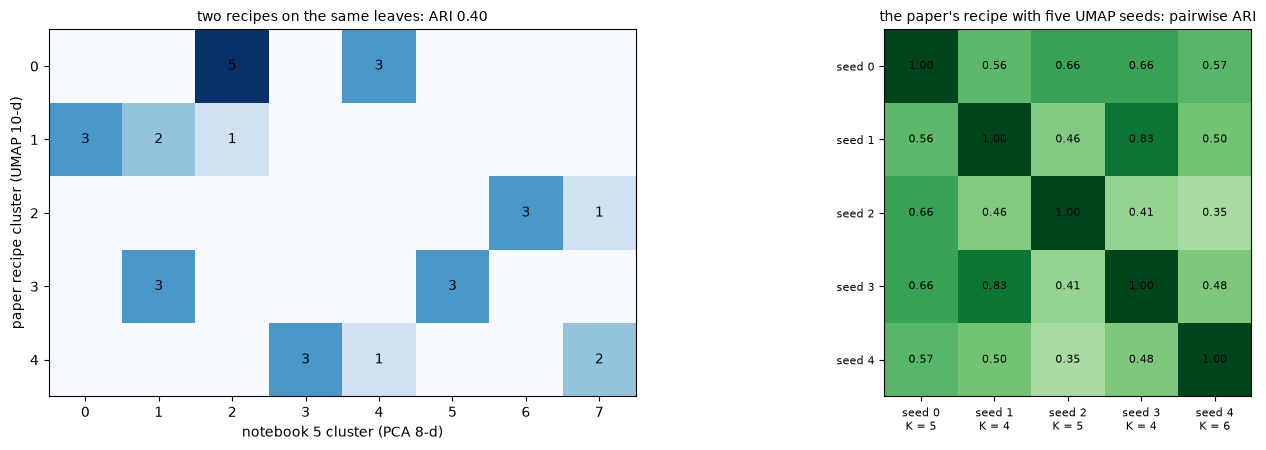

In [14]:
notebook5_labels = notebook5_model.predict(leaves_8d)
raptor_labels = raptor_model.predict(reduced)
table = np.zeros((raptor_k, notebook5_model.n_components), dtype=int)
for a, b in zip(raptor_labels, notebook5_labels):
    table[a, b] += 1

seed_runs = []
for seed in range(5):
    points = umap_reduce(leaf_vectors, min(RAPTOR_DIM, n - 2), seed)
    scores = [GaussianMixture(n_components=k, random_state=RAPTOR_SEED).fit(points).bic(points) for k in candidate_ks]
    k_seed = int(candidate_ks[np.argmin(scores)])
    seed_runs.append((k_seed, GaussianMixture(n_components=k_seed, random_state=0).fit(points).predict(points)))
agreement = np.array([[adjusted_rand_score(a, b) for _, b in seed_runs] for _, a in seed_runs])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
axes[0].imshow(table, cmap="Blues")
for i, j in zip(*np.nonzero(table)):
    axes[0].text(j, i, table[i, j], ha="center", va="center")
axes[0].set_xlabel(f"notebook 5 cluster (PCA {NOTEBOOK5_DIM}-d)")
axes[0].set_ylabel(f"paper recipe cluster (UMAP {reduced.shape[1]}-d)")
axes[0].set_title(f"two recipes on the same leaves: ARI {adjusted_rand_score(raptor_labels, notebook5_labels):.2f}")
axes[1].imshow(agreement, cmap="Greens", vmin=0, vmax=1)
for i in range(len(seed_runs)):
    for j in range(len(seed_runs)):
        axes[1].text(j, i, f"{agreement[i, j]:.2f}", ha="center", va="center", fontsize=8)
axes[1].set_xticks(range(len(seed_runs)))
axes[1].set_xticklabels([f"seed {s}\nK = {k}" for s, (k, _) in enumerate(seed_runs)], fontsize=8)
axes[1].set_yticks(range(len(seed_runs)))
axes[1].set_yticklabels([f"seed {s}" for s in range(len(seed_runs))], fontsize=8)
axes[1].set_title("the paper's recipe with five UMAP seeds: pairwise ARI")
fig.tight_layout()
plt.show()

The two recipes agree only partly. Every cluster of the paper's recipe combines pieces of two or three of notebook 5's clusters, and half of notebook 5's clusters are split between two of the paper's. And the paper's recipe does not even agree with itself across UMAP seeds – neither on the number of clusters (between 4 and 6) nor on their members (pairwise ARI between about 0.35 and 0.85). Both observations are the same lesson seen from two sides: on 30 leaves the clustering is under-determined, and the method, not the text, decides the details.

## What to take away

- The likelihood alone always prefers more clusters. BIC charges ½ ln *n* per parameter and works very well when every component has plenty of points – in our 2-D experiment from about 50 per component.
- It breaks down when components hold fewer points than dimensions: the covariances collapse, the likelihood grows without bound, and BIC chooses the largest *K* it is offered, or a minimum set by the balance between collapse and penalty.
- A single document's 30 leaves, clustered in 8 or 10 dimensions, are in that regime – in notebook 5 and in the paper's own recipe. The clusters still come out topically coherent, but their number is set by the method, not by the text.
- RAPTOR is designed for corpora with thousands of chunks, where the leaf layer has enough points per component. For small inputs – a single document, or the upper layers of any tree – keep the dimension well below the expected cluster size (two or three dimensions for 30 points), cap the number of clusters (as notebook 5's `n // 3` caps do) or bound the clusters by size (notebook 5's `MAX_CLUSTER_CHARS`), and treat BIC's *K* as a heuristic rather than a finding.

## Things to try

1. In section 3, use `covariance_type="spherical"`. Does BIC need fewer points per component to find *K* = 3?
2. In section 6, raise `reg_covar` to `1e-2` (about the natural variance of the PCA coordinates) for every fit. Does BIC still choose eight clusters?
3. Add the chunks of the three short documents of Examples 1–4 to the leaves (as notebook 5a does) and repeat section 6. With more points, does the BIC curve get a regular minimum?
4. Repeat section 7 with `n_components=2`. Is the chosen model regular now, and how many clusters does it find?
5. Replace BIC by AIC (`model.aic(points)`) in section 6. Which *K* does it choose – and why is that unsurprising after section 5?